# Tratamento de Dados

In [447]:
import pandas as pd
import numpy as np 
import scipy.stats as stats
import matplotlib.pyplot as plt

calls = pd.read_csv("C:/Users/Eva Custodio/Desktop/telecom_dataset_new.csv")
clients = pd.read_csv("C:/Users/Eva Custodio/Desktop/telecom_clients.csv")

#convertendo tipos
calls['date'] = pd.to_datetime(calls['date'])
clients['date_start'] = pd.to_datetime(clients['date_start'])
calls['internal'] = calls['internal'].astype(bool)

#removendo duplicadas
calls = calls.drop_duplicates()
clients = clients.drop_duplicates()

#alterando nulos
calls['operator_id'] = calls['operator_id'].fillna('Desconhecido')
calls['internal'] = calls['internal'].fillna('Desconhecido')

print(calls)
print(clients)

       user_id                      date direction  internal   operator_id  \
0       166377 2019-08-04 00:00:00+03:00        in     False  Desconhecido   
1       166377 2019-08-05 00:00:00+03:00       out      True      880022.0   
2       166377 2019-08-05 00:00:00+03:00       out      True      880020.0   
3       166377 2019-08-05 00:00:00+03:00       out      True      880020.0   
4       166377 2019-08-05 00:00:00+03:00       out     False      880022.0   
...        ...                       ...       ...       ...           ...   
53896   168606 2019-11-10 00:00:00+03:00       out      True      957922.0   
53897   168606 2019-11-10 00:00:00+03:00       out      True      957922.0   
53898   168606 2019-11-11 00:00:00+03:00       out      True      957922.0   
53899   168606 2019-11-15 00:00:00+03:00       out      True      957922.0   
53901   168606 2019-11-19 00:00:00+03:00        in     False  Desconhecido   

       is_missed_call  calls_count  call_duration  total_call_d

Na preparação, carreguei e analisei os dados. Converti a coluna 'internal' de object para bool a fim de ocupar menos espaço. Converti as colunas date para tipo datetime para analisar as datas. Removi as duplicadas. As colunas Operator_ID (8.172 dados nulo) e Internal (117 dados nulo), foram substituidas pela palavra 'Desconhecido' para que futuramente não seja disperdiçado os dados a serem analisados.

# Classificação de produtividade

In [448]:
#  tempo de espera
calls['waiting_time'] = calls['total_call_duration'] - calls['call_duration']

# separando direção de chamadas
out_calls = calls[calls['direction'] == 'out']
in_calls = calls[calls['direction'] == 'in']

#total de chamada recebida
in_total = in_calls.groupby('operator_id')['calls_count'].sum().reset_index().rename(columns={"calls_count": "in_calls"})

#total de chamada realizada
out_total = out_calls.groupby('operator_id')['calls_count'].sum().reset_index().rename(columns={"calls_count": "out_calls"})

#chamadas perdidas
missed_calls = in_calls[in_calls['is_missed_call'] == True].groupby('operator_id')['calls_count'].sum().reset_index().rename(columns={"calls_count": "missed_calls"})

#tempo médio de espera
avg_waiting_time = calls.groupby('operator_id')['waiting_time'].mean().reset_index()

# Dias ativos 
active_days = out_calls.groupby('operator_id')['date'].nunique().reset_index()

operators_unique = calls[['operator_id']].drop_duplicates()

a = operators_unique.merge(in_total, how='left', on="operator_id").merge(out_total, how='left', on="operator_id").merge(active_days, how='left', on="operator_id").merge(missed_calls, how='left', on="operator_id")

#produtividade out (realizada)
a['out_prod'] = a['out_calls'] / a['date']

#produtividade in (recebida)
a['in_prod'] = a['in_calls'] / a['date']

a

,operator_id,in_calls,out_calls,date,missed_calls,out_prod,in_prod
0,Desconhecido,104043.0,521.0,71.0,103397.0,7.338028,1465.394366
1,880022.0,8.0,189.0,36.0,NaN,5.250000,0.222222
2,880020.0,7.0,38.0,7.0,NaN,5.428571,1.000000
3,881278.0,NaN,20.0,5.0,NaN,4.000000,NaN
4,880028.0,63.0,2497.0,78.0,NaN,32.012821,0.807692
...,...,...,...,...,...,...,...
1088,958394.0,22.0,NaN,NaN,NaN,NaN,NaN
1089,952914.0,78.0,580.0,19.0,NaN,30.526316,4.105263
1090,952916.0,1.0,7.0,4.0,NaN,1.750000,0.250000
1091,959118.0,NaN,14.0,4.0,NaN,3.500000,NaN


In [449]:
#taxa chamadas perdidas 
a['missed_rate'] = a['missed_calls'] / a['in_calls'].replace(0, np.nan)

#calculando percentil 
a['out_prod'].quantile([0.25, 0.50, 0.75])
a['in_prod'].quantile([0.25, 0.50, 0.75])

p25_out = a['out_prod'].quantile(0.25)
p50_out = a['out_prod'].quantile(0.50)
p75_out = a['out_prod'].quantile(0.75)

def classificar_produtividade(x):
    if x >= p75_out:
        return 'Produtividade alta'
    elif x >= p50_out:
        return 'Produtividade média'
    else:
        return 'Produtividade baixa'

a['nivel_produtividade'] = a['out_prod'].apply(classificar_produtividade)

#os mais produtivos 
top_prod = a['out_prod'].quantile(0.90)
melhores = a[a['out_prod'] >= top_prod].reset_index()

#os menos produtivos 
bad_prod = a['out_prod'].quantile(0.25)
bad = a[a['out_prod']<= bad_prod].reset_index()

a = a.merge(avg_waiting_time, how='left', on='operator_id')

a


,operator_id,in_calls,out_calls,date,missed_calls,out_prod,in_prod,missed_rate,nivel_produtividade,waiting_time
0,Desconhecido,104043.0,521.0,71.0,103397.0,7.338028,1465.394366,0.993791,Produtividade média,170.209898
1,880022.0,8.0,189.0,36.0,NaN,5.250000,0.222222,NaN,Produtividade baixa,53.971429
2,880020.0,7.0,38.0,7.0,NaN,5.428571,1.000000,NaN,Produtividade baixa,14.000000
3,881278.0,NaN,20.0,5.0,NaN,4.000000,NaN,NaN,Produtividade baixa,9.750000
4,880028.0,63.0,2497.0,78.0,NaN,32.012821,0.807692,NaN,Produtividade alta,210.178218
...,...,...,...,...,...,...,...,...,...,...
1088,958394.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,Produtividade baixa,15.700000
1089,952914.0,78.0,580.0,19.0,NaN,30.526316,4.105263,NaN,Produtividade alta,190.530612
1090,952916.0,1.0,7.0,4.0,NaN,1.750000,0.250000,NaN,Produtividade baixa,40.000000
1091,959118.0,NaN,14.0,4.0,NaN,3.500000,NaN,NaN,Produtividade baixa,47.000000


# Gráficos de Análise

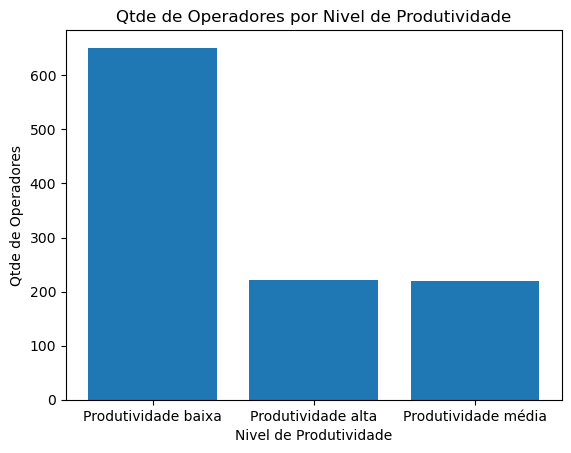

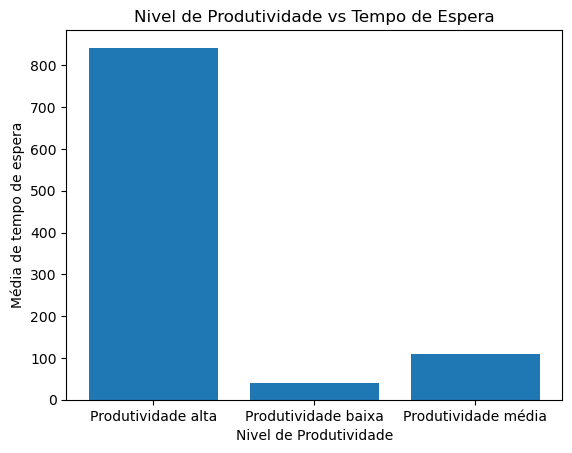

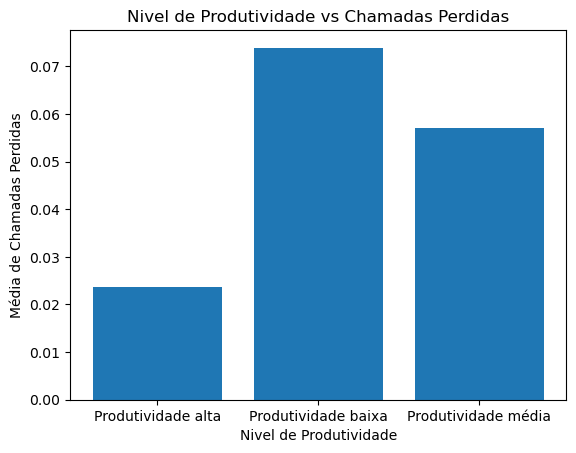

In [450]:
media_waiting = a.groupby('nivel_produtividade')['waiting_time'].mean()
media_missed = a.groupby('nivel_produtividade')['missed_rate'].mean()
contagem = a['nivel_produtividade'].value_counts()


plt.bar(contagem.index, contagem.values)
plt.title('Qtde de Operadores por Nivel de Produtividade')
plt.xlabel('Nivel de Produtividade')
plt.ylabel('Qtde de Operadores')
plt.show()


plt.bar(media_waiting.index, media_waiting.values)
plt.title('Nivel de Produtividade vs Tempo de Espera')
plt.xlabel('Nivel de Produtividade')
plt.ylabel('Média de tempo de espera')
plt.show()


plt.bar(media_missed.index, media_missed.values)
plt.title('Nivel de Produtividade vs Chamadas Perdidas')
plt.xlabel('Nivel de Produtividade')
plt.ylabel('Média de Chamadas Perdidas')
plt.show()

# Estatísticas descritivas

In [451]:
# média e variância 
print('*****PRODUTIVIDADE OUT*****')
media_out = a['out_prod'].mean()
variancia_out = a['out_prod'].var()
print(f'A media e: {media_out:.2f}') 
print(f'A variancia e: {variancia_out:.2f}')
print()

print('*****PRODUTIVIDADE IN *****')
media_in = a['in_prod'].mean()
variancia_in = a['in_prod'].var()
print(f'A media e: {media_in:.2f}')
print(f'A variancia e: {variancia_in:.2f}')
print()

print('*****TEMPO DE ESPERA *****')
media_waiting = a['waiting_time'].mean()
variancia_waiting = a['waiting_time'].var()
print(f'A média é: {media_waiting: .2f}')
print(f'A variância é: {variancia_waiting: .2f}')
print()

print('*****TAXA DE CHAMADAS PERDIDAS*****')
media_missed = a['missed_rate'].mean()
variancia_missed = a['missed_rate'].var()
print(f'A média é: {media_missed: .2f}')
print(f'A variância é: {variancia_missed: .2f}')
print()
  

*****PRODUTIVIDADE OUT*****
A media e: 29.37
A variancia e: 4490.89

*****PRODUTIVIDADE IN *****
A media e: 14.57
A variancia e: 7135.60

*****TEMPO DE ESPERA *****
A média é:  216.04
A variância é:  256812.18

*****TAXA DE CHAMADAS PERDIDAS*****
A média é:  0.06
A variância é:  0.02



Produtividade OUT: 
Em média, cada operador realiza aproximadamente 29 chamadas de saída no período analisado e a variância está  alta. Isso significa que provavelmente alguns operadores fazem muitas chamadas, enquanto outros fazem pouca, ou seja, existe forte desigualdade de produtividade. 

Produtividade IN: 
Em média, cada operador recebe aproximadamente 15 chamadas no período analisado, e a variância está ainda mais alta que as ligações recebidas. Isso significa que a distribuição de chamadas está sendo feita de forma desigual, ou seja, a entrada de chamadas está ainda mais desorganizada que a saída.

Tempo de espera: 
O tempo médio de espera é de 216 segundos (3 minutos e meio), e a variância ainda mais alta. Isso significa que algumas chamadas esperam poucos segundos, enquanto outras esperam muitos minutos, ou seja, a experiência não é única, cada ligação tem um tempo de espera diferente.

Taxa de chamadas perdidas: 
Em média, a empresa tem 6% de chamadas perdidas com uma variância significativamente baixa, o que significa que a maioria dos operadores possui taxas parecidas, ou seja, não está concentrada em somente alguns operadores. 

# Testes de hipóteses:

**Tempo médio de espera:**

H₀: O tempo médio de espera dos operadores mais produtivos é igual ao dos menos produtivos.

H₁: O tempo médio de espera dos operadores mais produtivos é diferente dos menos produtivos


In [452]:
top_group = a[a['nivel_produtividade'] == 'Produtividade alta']['waiting_time'].dropna()
low_group = a[a['nivel_produtividade'] == 'Produtividade baixa']['waiting_time'].dropna()

alpha = 0.05
statistic, p_value = stats.ttest_ind(top_group, low_group)

print("***Teste de hipóteses de tempo de espera entre operadores mais produtivos e menos produtivos***")
print(f"Estatística do teste: {statistic:.4f}")

print(f"Valor p: {p_value:.10f}")
print(f"Nível de significância: {alpha}")
print()
if p_value < alpha:
    print("Resultado: Rejeitamos a hipótese nula")
    print("Conclusão: Há evidência estatística de que o tempo de espera entre os operadores mais e menos produtivos são diferentes")
else:
    print("Resultado: Não rejeitamos a hipótese nula")
    print("Conclusão: Não há evidência estatística suficiente para afirmar que o tempo de espera entre os operadores mais e menos produtivos são diferentes")
print()

***Teste de hipóteses de tempo de espera entre operadores mais produtivos e menos produtivos***
Estatística do teste: 23.4176
Valor p: 0.0000000000
Nível de significância: 0.05

Resultado: Rejeitamos a hipótese nula
Conclusão: Há evidência estatística de que o tempo de espera entre os operadores mais e menos produtivos são diferentes



Tempo de espera entre operadores: (Clientes possuem experiências inconsistentes)

O tempo de espera apresenta diferença estatisticamente significativa entre operadores mais e menos produtivos, indicando impacto direto da produtividade operacional na experiência do cliente, muito provavelmente operadores mais produtivos reduzem filas, tornando o atendimento mais ágil.

Como sugestão: Adicionar mais operadores em horários de pico (com maior número de registro de ligações), ou desenvolver ligação de retorno automático quando a fila estiver alta, assim que o operador estiver disponível.

Taxa de chamadas perdidas:

H₀: A taxa de chamadas perdidas dos operadores mais produtivos é igual à dos menos produtivos.

H₁: A taxa de chamadas perdidas dos operadores mais produtivos é diferente à dos menos produtivos.

In [454]:
top_group = a[a['nivel_produtividade'] == 'Produtividade alta']['missed_rate'].dropna()
low_group = a[a['nivel_produtividade'] == 'Produtividade baixa']['missed_rate'].dropna()

alpha = 0.05
statistic, p_value = stats.ttest_ind(top_group, low_group)

print("***Teste de hipóteses de taxa de chamadas perdidas entre operadores mais produtivos e menos produtivos***")
print(f"Estatística do teste: {statistic:.4f}")
print(f"Valor p: {p_value:.10f}")
print(f"Nível de significância: {alpha}")
print()
if p_value < alpha:
    print("Resultado: Rejeitamos a hipótese nula")
    print("Conclusão: Há evidência estatística que a taxa de chamadas perdidas entre operadores mais ou menos produtivos são diferentes")
else:
    print("Resultado: Não rejeitamos a hipótese nula")
    print("Conclusão: Não há evidência estatística suficiente para afirmar que a taxa de chamadas perdidas entre operadores mais ou e menos produtivos são diferentes")
print()


***Teste de hipóteses de taxa de chamadas perdidas entre operadores mais produtivos e menos produtivos***
Estatística do teste: -3.1095
Valor p: 0.0021922240
Nível de significância: 0.05

Resultado: Rejeitamos a hipótese nula
Conclusão: Há evidência estatística que a taxa de chamadas perdidas entre operadores mais ou menos produtivos são diferentes



Taxa de chamadas perdidas: (Parte dos clientes desistem ou não conseguem atendimento)

Operadores mais produtivos possuem taxa de perda diferente dos menos produtivos, então muito provavelmente os produtivos perdem menos chamadas.

Como sugestão: Evitar concentração excessiva em poucos operadores, implementar retorno automático de ligação, e permitir que o supervisor tenha alertas em tempo real de taxa de chamadas perdidas, estabelecer a porcentagem aceitável na empresa. 